# Aulas IA Preditiva Modulo1 Semana 08 Aula1

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

referencia = pd.Timestamp("2026-09-30")
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="pastel" # "Set2", "muted"
)

plt.rcParams.update({
    "figure.figsize": (10, 5), "font.size": 11,
    "axes.facecolor": "#F7FAFC", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 14,
    "axes.titlepad": 18, "grid.alpha": 0.28,
    "grid.color": "#A6BBC7", "axes.edgecolor": "#CBD5DD"
})

print("Referência:", referencia.date())
print("Dados fictícios para uso didático.")


Referência: 2026-09-30
Dados fictícios para uso didático.


In [73]:
df = pd.read_csv("dados_rh.csv", encoding="utf-8-sig")

df = df.rename(columns={
    "ID": "id", "nome de integrante": "nome",
    "salário": "salario", "faixa de idade": "faixa_idade",
    "data de contratação": "data_contratacao",
    "status do integrante": "status"
})
print("Dimensões:", df.shape)
#print(df.head(4).to_string(index=False))

df.head(15)


Dimensões: (2400, 10)


,id,nome,salario,cargo,idade,faixa_idade,sexo,data_contratacao,status,departamento
0,0,Anna Liz Sampaio,4163.00,Baterista,65,60-69,Masculino,2020-01-23,Ativo,administrativo
1,1,Noah Abreu,9886.00,Cientista da informação e documentação,63,60-69,Feminino,2022-11-29,Ativo,administrativo
2,2,Sra. Julia da Rosa,8026.00,Optometrista,58,50-59,Feminino,2020-02-11,Inativo,administrativo
3,3,Pietro Ramos,7797.00,Mensageiro,22,20-29,Feminino,2020-07-09,Inativo,administrativo
4,4,Bruno Ferreira Esteves,2526.17,Assistente comercial,45,40-49,Feminino,2023-06-15,Ativo,comercial
5,5,Valéria Costa Gomes,4864.94,Analista de RH,29,20-29,Masculino,2022-10-10,Ativo,recursos humanos
6,6,Gabriela Vieira Nascimento,4257.53,Técnico de suporte,30,30-39,Masculino,2024-03-21,Ativo,tecnologia
7,7,Gabriela Lima Teixeira,5229.87,Analista de operações,26,20-29,Masculino,2019-01-19,Ativo,operações
8,8,João Almeida Almeida,7101.61,Consultor comercial,56,50-59,Feminino,2020-03-09,Ativo,comercial
9,9,Camila Nascimento Nascimento,4827.78,Analista de operações,49,40-49,Masculino,2025-12-11,Ativo,operações


In [74]:
print(df.describe())

                id       salario        idade
count  2400.000000   2400.000000  2400.000000
mean   1199.500000   5714.192917    41.916667
std     692.964646   2942.725061    10.439515
min       0.000000   2100.130000    20.000000
25%     599.750000   3355.365000    34.000000
50%    1199.500000   5048.985000    42.000000
75%    1799.250000   7309.012500    49.000000
max    2399.000000  17687.090000    68.000000


In [75]:
print(df.dtypes)

print(list(df.columns))

id                    int64
nome                 object
salario             float64
cargo                object
idade                 int64
faixa_idade          object
sexo                 object
data_contratacao     object
status               object
departamento         object
dtype: object
['id', 'nome', 'salario', 'cargo', 'idade', 'faixa_idade', 'sexo', 'data_contratacao', 'status', 'departamento']


In [76]:
# Convertendo para datetime

df["data_contratacao"] = pd.to_datetime(df["data_contratacao"], format="%Y-%m-%d")
df["ano"] = df["data_contratacao"].dt.year
df["mes"] = df["data_contratacao"].dt.month
df["trimestre"] = df["data_contratacao"].dt.to_period("Q")
df["anos_desde_admissao"] = (
    (referencia - df["data_contratacao"]).dt.days / 365.2425
)

print(df.dtypes)

df.head(5)


id                              int64
nome                           object
salario                       float64
cargo                          object
idade                           int64
faixa_idade                    object
sexo                           object
data_contratacao       datetime64[ns]
status                         object
departamento                   object
ano                             int32
mes                             int32
trimestre               period[Q-DEC]
anos_desde_admissao           float64
dtype: object


,id,nome,salario,cargo,idade,faixa_idade,sexo,data_contratacao,status,departamento,ano,mes,trimestre,anos_desde_admissao
0,0,Anna Liz Sampaio,4163.00,Baterista,65,60-69,Masculino,2020-01-23,Ativo,administrativo,2020,1,2020Q1,6.685969
1,1,Noah Abreu,9886.00,Cientista da informação e documentação,63,60-69,Feminino,2022-11-29,Ativo,administrativo,2022,11,2022Q4,3.835808
2,2,Sra. Julia da Rosa,8026.00,Optometrista,58,50-59,Feminino,2020-02-11,Inativo,administrativo,2020,2,2020Q1,6.633949
3,3,Pietro Ramos,7797.00,Mensageiro,22,20-29,Feminino,2020-07-09,Inativo,administrativo,2020,7,2020Q3,6.226001
4,4,Bruno Ferreira Esteves,2526.17,Assistente comercial,45,40-49,Feminino,2023-06-15,Ativo,comercial,2023,6,2023Q2,3.293702


In [77]:
# funcoes de mostrar dataframe
def mostrar(tabela, num_show=8):
    print(tabela.head(num_show).round(2).to_string(index=False))

plano = pd.DataFrame({
    "departamento": ["administrativo", "comercial", "financeiro",
                     "operações", "recursos humanos", "tecnologia"],
    "quadro_planejado": [300, 410, 250, 540, 210, 400],
    "orcamento_mensal": [1600, 2500, 1650, 2400, 1300, 3700]
})

mostrar(plano)

    departamento  quadro_planejado  orcamento_mensal
  administrativo               300              1600
       comercial               410              2500
      financeiro               250              1650
       operações               540              2400
recursos humanos               210              1300
      tecnologia               400              3700


In [78]:
mostrar(df)

 id                       nome  salario                                  cargo  idade faixa_idade      sexo data_contratacao  status     departamento  ano  mes trimestre  anos_desde_admissao
  0           Anna Liz Sampaio  4163.00                              Baterista     65       60-69 Masculino       2020-01-23   Ativo   administrativo 2020    1    2020Q1                 6.69
  1                 Noah Abreu  9886.00 Cientista da informação e documentação     63       60-69  Feminino       2022-11-29   Ativo   administrativo 2022   11    2022Q4                 3.84
  2         Sra. Julia da Rosa  8026.00                           Optometrista     58       50-59  Feminino       2020-02-11 Inativo   administrativo 2020    2    2020Q1                 6.63
  3               Pietro Ramos  7797.00                             Mensageiro     22       20-29  Feminino       2020-07-09 Inativo   administrativo 2020    7    2020Q3                 6.23
  4     Bruno Ferreira Esteves  2526.17      

In [79]:
def barras_vertical(tabela, categoria, valor, titulo=None):
    '''
    Param:
    tabela: dataframe
    categoria: str
    valor: str
    titulo: str
    '''
    fig, ax = plt.subplots()
    sns.barplot(data=tabela, x=categoria, y=valor, hue=categoria,
                legend=False, errorbar=None,
                orient="v", width=0.72, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel(categoria.replace("_", " ").capitalize())
    ax.set_ylabel(valor.replace("_", " ").capitalize())
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.18)
    ax.tick_params(axis="x", labelrotation=28)
    for grupo in ax.containers:
        ax.bar_label(grupo, fmt="%.0f", padding=4, fontsize=10)
    sns.despine(ax=ax, left=True, bottom=True) # remover bordas
    fig.tight_layout() #ajusta automaticamente os espaçoes
    plt.show()


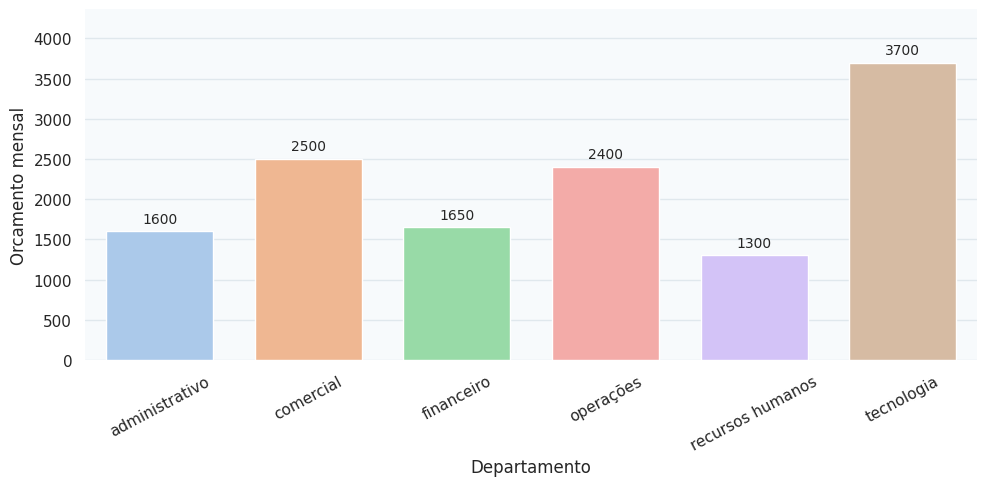

In [86]:
barras_vertical(plano, "departamento", "orcamento_mensal")

In [41]:
def barras_horizontal(tabela, categoria, valor, titulo=None):
    '''
    Param:
    tabela: dataframe
    categoria: str
    valor: str
    titulo: str
    '''
    fig, ax = plt.subplots()
    sns.barplot(data=tabela, x=valor, y=categoria, hue=categoria,
                legend=False, errorbar=None,
                orient="h", width=0.72, ax=ax)
    ax.set_title(titulo, loc="center")
    ax.set_xlabel(valor.replace("_", " ").capitalize())
    ax.set_ylabel(categoria.replace("_", " ").capitalize())
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.2)
    for grupo in ax.containers:
        ax.bar_label(grupo, fmt="%.0f", padding=4, fontsize=10)
    sns.despine(ax=ax, left=True, bottom=True)
    fig.tight_layout()
    plt.show()


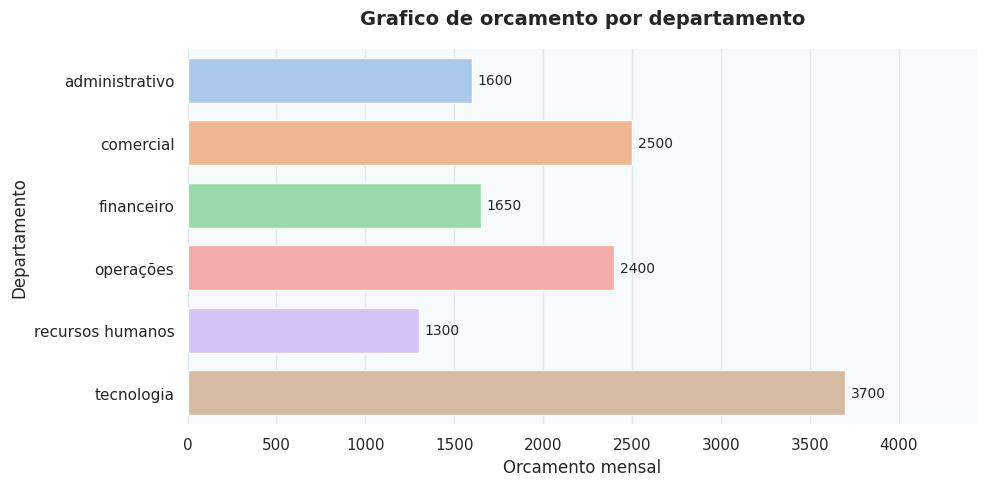

In [87]:
barras_horizontal(plano, "departamento", "orcamento_mensal", "Grafico de orcamento por departamento")

In [ ]:
# grafico de pizza com porcentagem
def pizza(tabela, rotulo, valor, titulo=None):
    '''
    Param:
    tabela: dataframe
    rotulo: str
    valor: str
    titulo: str
    '''
    fig, ax = plt.subplots()
    ax.pie(tabela[valor], labels=tabela[rotulo],
           autopct="%1.1f%%", startangle=90, pctdistance=0.7,
           wedgeprops={"edgecolor": "white", "linewidth": 2},
           textprops={"color": "#23373B", "fontsize": 12})
    ax.set_title(titulo)
    ax.axis("equal")
    fig.tight_layout()
    plt.show()


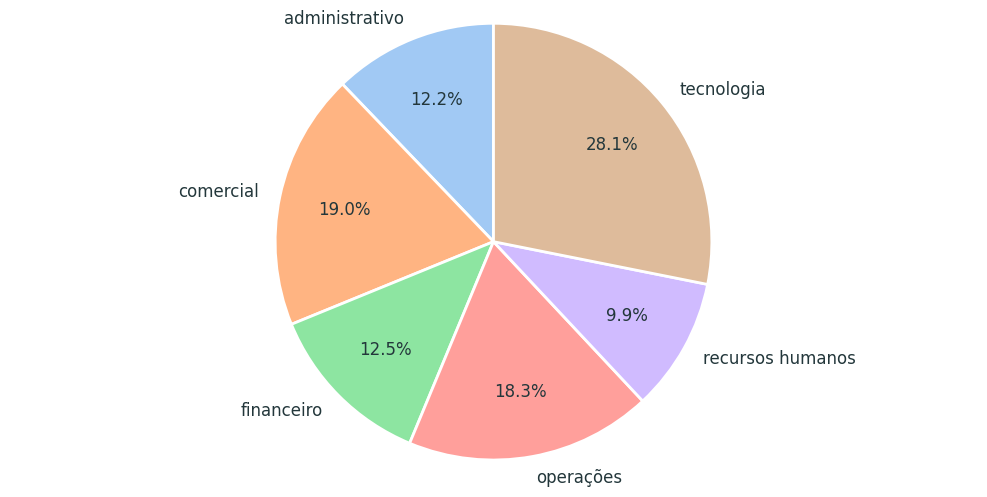

In [88]:
pizza(plano, "departamento", "orcamento_mensal")

In [62]:
# grafico de dispersão
def dispersao(tabela, x, y, titulo=None):
    '''
    Param:
    tabela: dataframe
    x: str
    y: str
    titulo: str
    '''
    fig, ax = plt.subplots()
    sns.scatterplot(data=tabela, x=x, y=y,
                    alpha=0.5, s=35, color="#2A7F87",
                    edgecolor="white", linewidth=0.35, ax=ax)
    ax.set_title(titulo.replace("_", " "))
    ax.set_ylabel(y.replace("_", " "))
    ax.set_xlabel(x.replace("_", " "))
    sns.despine(ax=ax)
    fig.tight_layout()
    plt.show()

print("Função dispersao disponível.")


Função dispersao disponível.


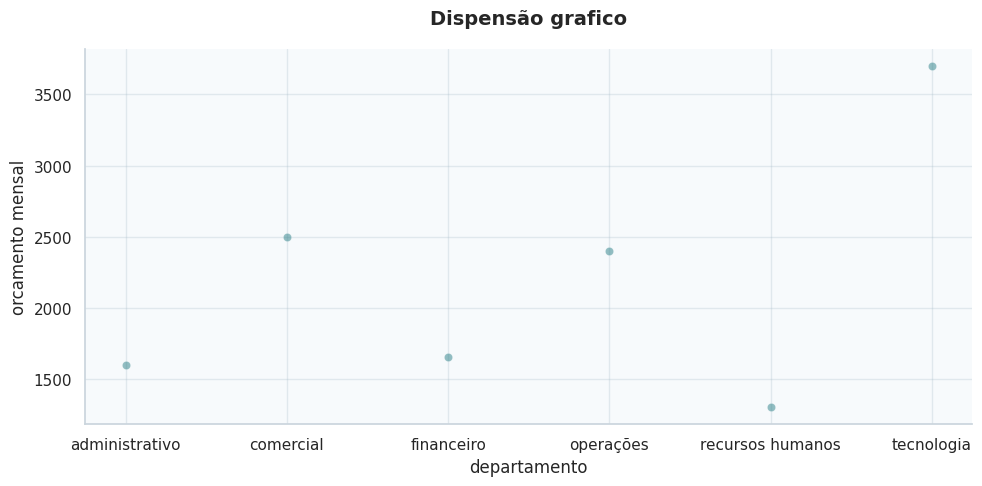

In [83]:
dispersao(plano, "departamento", "orcamento_mensal", "Dispensão_grafico")

In [69]:
def linhas(tabela, x, y, mark='o', titulo=None):    
    '''
    Param:
    tabela: dataframe
    x: str
    y: str
    titulo: str
    '''
    fig, ax = plt.subplots()
    sns.lineplot(data=tabela, x=x, y=y,
                 marker=mark, markersize=7, linewidth=1.8,
                 color="#2A7F87", ax=ax)
    ax.set_title(titulo)
    sns.despine(ax=ax)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

print("Função linhas disponível.")


Função linhas disponível.


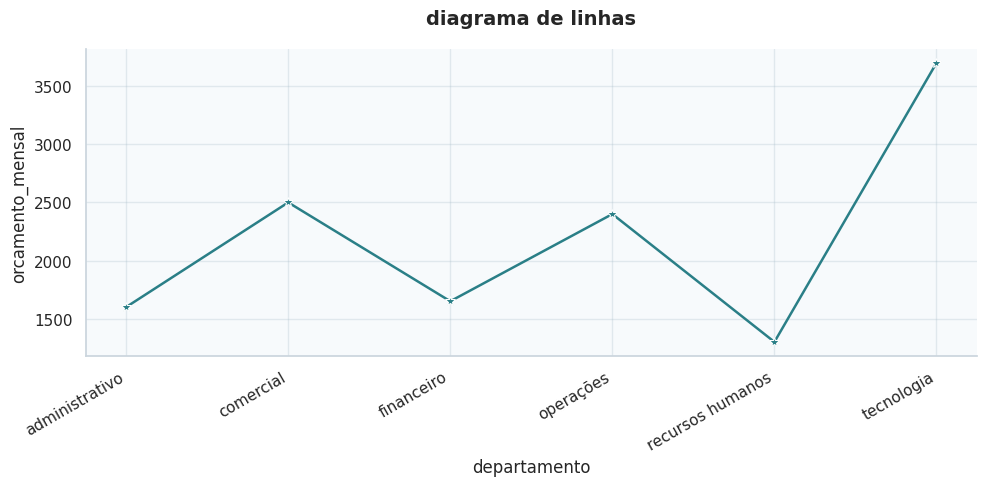

In [84]:
linhas(plano, "departamento", "orcamento_mensal", mark='*', titulo="diagrama de linhas")

### Qual é o tamanho do quadro ativo e inativo?

 status  funcionarios
  Ativo          1888
Inativo           512


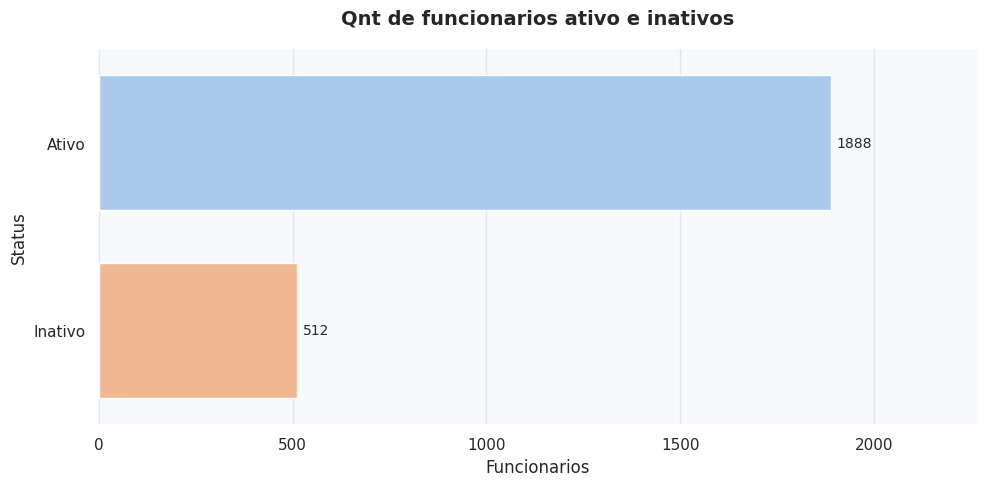

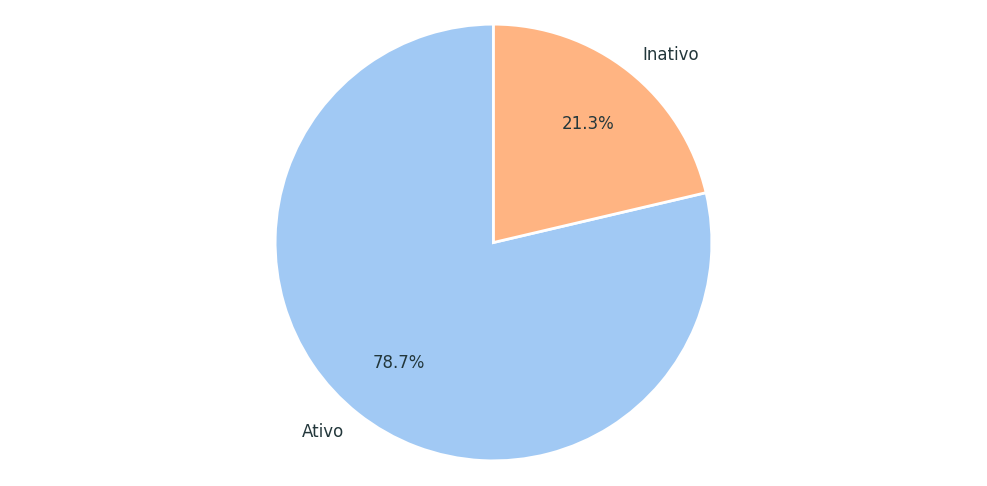

In [97]:
quadro = df.groupby("status").size().reset_index(name="funcionarios")
mostrar( quadro )

barras_horizontal(quadro, "status", "funcionarios", titulo="Qnt de funcionarios ativo e inativos")

pizza(quadro, "status", "funcionarios")


### Quais departamentos têm mais pessoas ativas?

 id                         nome  salario                                  cargo  idade faixa_idade      sexo data_contratacao status     departamento  ano  mes trimestre  anos_desde_admissao
  0             Anna Liz Sampaio  4163.00                              Baterista     65       60-69 Masculino       2020-01-23  Ativo   administrativo 2020    1    2020Q1                 6.69
  1                   Noah Abreu  9886.00 Cientista da informação e documentação     63       60-69  Feminino       2022-11-29  Ativo   administrativo 2022   11    2022Q4                 3.84
  4       Bruno Ferreira Esteves  2526.17                   Assistente comercial     45       40-49  Feminino       2023-06-15  Ativo        comercial 2023    6    2023Q2                 3.29
  5          Valéria Costa Gomes  4864.94                         Analista de RH     29       20-29 Masculino       2022-10-10  Ativo recursos humanos 2022   10    2022Q4                 3.97
  6   Gabriela Vieira Nascimento  4257.5

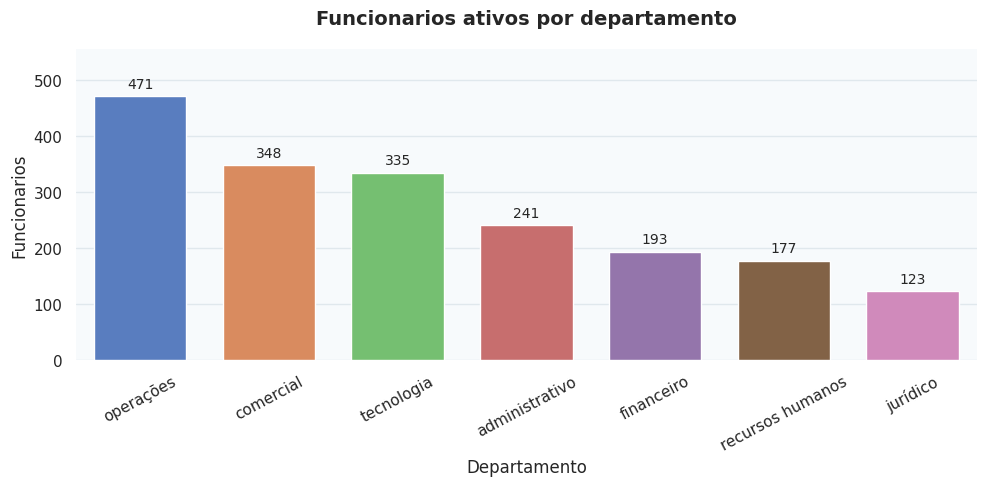

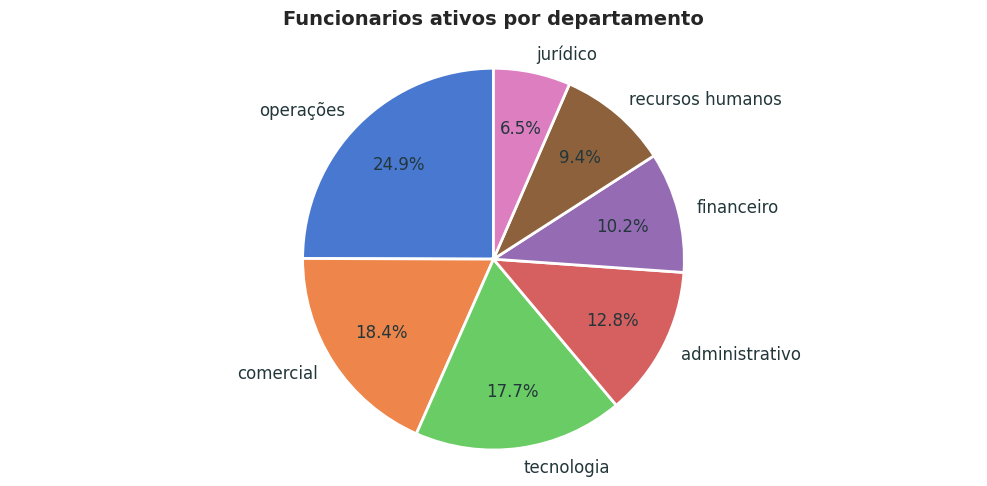

In [121]:
ativos = df.loc[df["status"] == "Ativo"].copy()
mostrar(ativos)

print("\nQuais departamento tenho: ", list(df["departamento"].unique()), "\n")

pessoas_ativas_departamento = ativos.groupby("departamento").size() \
                                .reset_index(name="funcionarios") \
                                .sort_values("funcionarios", ascending=False)

mostrar(pessoas_ativas_departamento)

barras_vertical(pessoas_ativas_departamento, "departamento", "funcionarios", titulo="Funcionarios ativos por departamento")

pizza(pessoas_ativas_departamento, "departamento", "funcionarios", titulo="Funcionarios ativos por departamento")

### Como a folha mensal (salario) se distribui por departamento?

 id                         nome  salario                                  cargo  idade faixa_idade      sexo data_contratacao status     departamento  ano  mes trimestre  anos_desde_admissao
  0             Anna Liz Sampaio  4163.00                              Baterista     65       60-69 Masculino       2020-01-23  Ativo   administrativo 2020    1    2020Q1                 6.69
  1                   Noah Abreu  9886.00 Cientista da informação e documentação     63       60-69  Feminino       2022-11-29  Ativo   administrativo 2022   11    2022Q4                 3.84
  4       Bruno Ferreira Esteves  2526.17                   Assistente comercial     45       40-49  Feminino       2023-06-15  Ativo        comercial 2023    6    2023Q2                 3.29
  5          Valéria Costa Gomes  4864.94                         Analista de RH     29       20-29 Masculino       2022-10-10  Ativo recursos humanos 2022   10    2022Q4                 3.97
  6   Gabriela Vieira Nascimento  4257.5

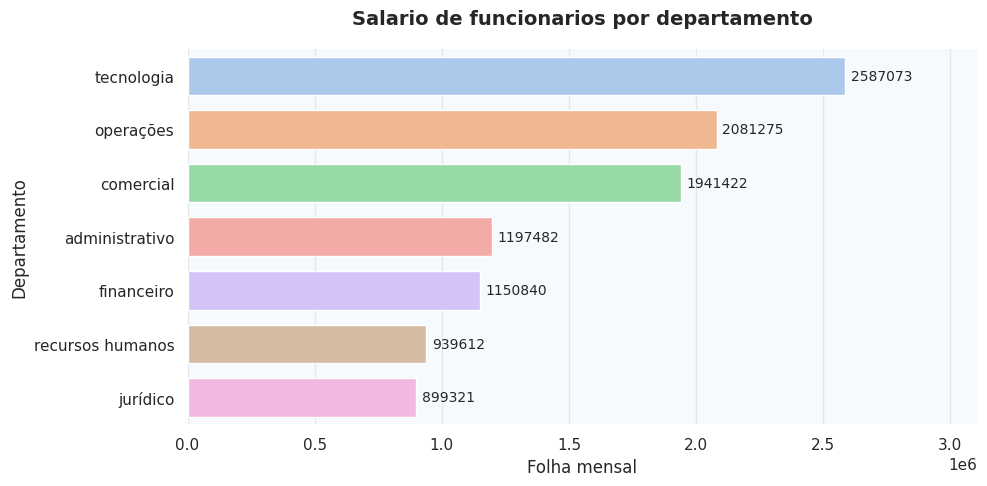

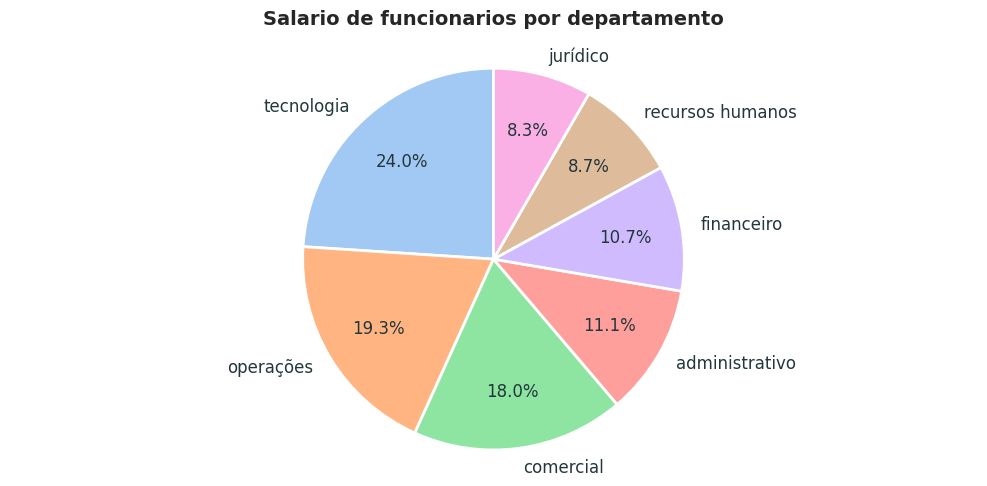

In [ ]:
ativos = df.loc[df["status"] == "Ativo"].copy()
mostrar(ativos)

print("")
df_departamento_salario = ativos.groupby("departamento")["salario"].sum() \
                            .reset_index(name="folha_mensal")\
                            .sort_values("folha_mensal", ascending=False)

mostrar(df_departamento_salario)

barras_horizontal(df_departamento_salario, "departamento", "folha_mensal", "Salario de funcionarios por departamento")

pizza(df_departamento_salario, "departamento", "folha_mensal", "Salario de funcionarios por departamento")
